# Day 9 — K-Means, Hierarchical Clustering và STING (đầy đủ sơ đồ trên đồ thị 2D)

Tài liệu ôn tập thực hành theo trọn bộ **48 slide bài giảng Day 9: Clustering** (ThS. Lê Minh Tân — HCMUTE),
đối chiếu từng bước trực quan giữa **K-Means**, **Hierarchical Clustering (HC)** và **STING** (đề tài nhóm 15).

In [1]:
import copy
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, FancyArrowPatch, Rectangle
import numpy as np
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import cdist
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "sting.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook trong repo có src/sting.py")
sys.path.insert(0, str(ROOT / "src"))
from sting import STING

plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
PAL = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9"]
SEED = 42
print("Đã nạp thư viện và mã nguồn STING.")

Đã nạp thư viện và mã nguồn STING.


## 1. Dữ liệu hai cột ngẫu nhiên (Homework slide 48)

`make_blobs` sinh 3 nhóm Gauss, thêm 12 điểm nhiễu rải đều (tổng 162 điểm × 2 cột). Thuật toán phân cụm chỉ thấy ma trận `X`, không thấy nhãn thật.

Kích thước dữ liệu: (162, 2)


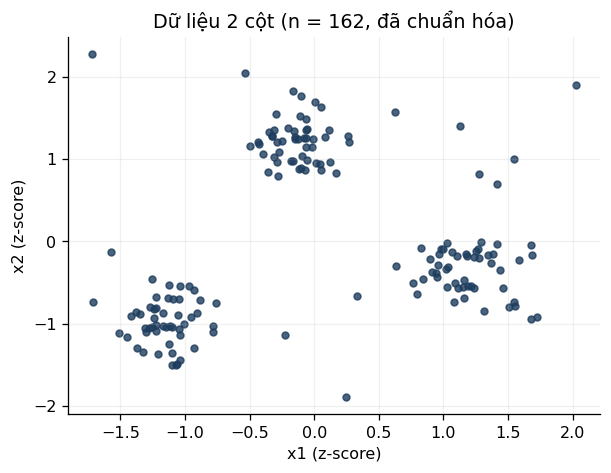

In [2]:
rng = np.random.default_rng(SEED)
X_blobs, truth = make_blobs(n_samples=150, centers=[(-4, -3), (0, 4), (5, -1)],
                            cluster_std=[0.9, 0.8, 1.0], random_state=SEED)
X_noise = rng.uniform(low=[-8, -7], high=[9, 8], size=(12, 2))
X = StandardScaler().fit_transform(np.vstack([X_blobs, X_noise]))
print("Kích thước dữ liệu:", X.shape)

fig, ax = plt.subplots(figsize=(5.2, 4.0), layout="constrained")
ax.scatter(X[:, 0], X[:, 1], s=18, c="#1E3D5E", alpha=0.8)
ax.set_title("Dữ liệu 2 cột (n = 162, đã chuẩn hóa)")
ax.set_xlabel("x1 (z-score)")
ax.set_ylabel("x2 (z-score)")
ax.grid(alpha=0.18)
plt.show()

## 2. K-Means từng bước, Bẫy khởi tạo (TRAP!) và WCSS / Elbow

### 2.1 Bốn bước K-Means trên đồ thị 2D (slides 11–16)
Theo dõi 4 giai đoạn: **(1) Đặt k tâm ban đầu → (2) Gán điểm theo tâm gần nhất → (3) Cập nhật tâm về trung bình cụm → (4) Lặp đến khi hội tụ**.

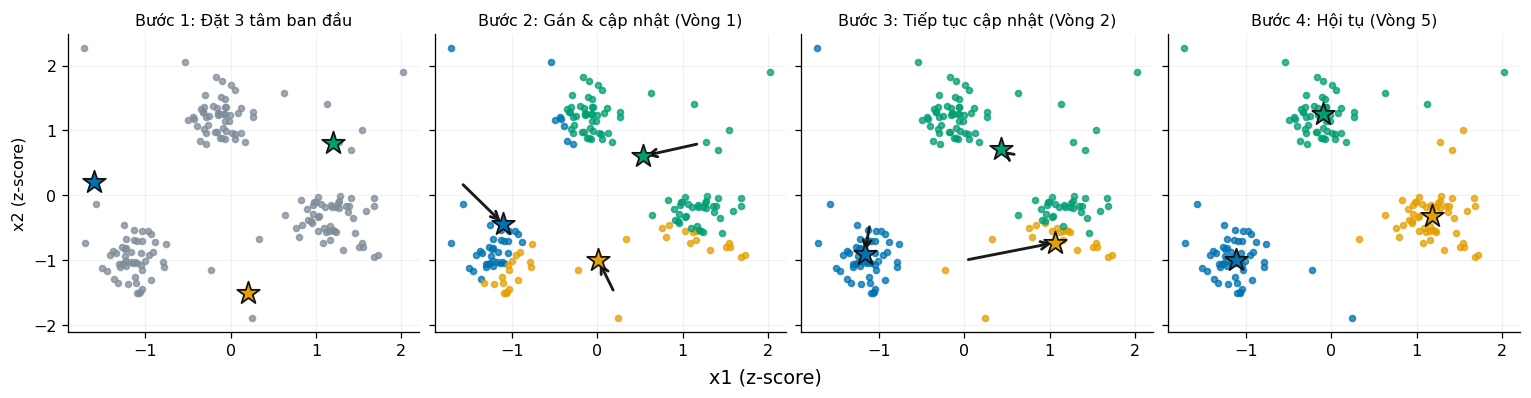

In [3]:
# Cố tình đặt tâm lệch để nhìn rõ chuyển động qua các vòng
centroids = np.array([[-1.6, 0.2], [0.2, -1.5], [1.2, 0.8]], dtype=float)
history = [(centroids.copy(), None)]
for _ in range(12):
    dists = cdist(X, centroids)
    labs = np.argmin(dists, axis=1)
    new_c = np.array([X[labs == i].mean(axis=0) for i in range(3)])
    history.append((new_c.copy(), labs.copy()))
    if np.allclose(new_c, centroids, atol=1e-4):
        break
    centroids = new_c

pick_idx = [0, 1, 2, len(history) - 1]
step_names = (
    "Bước 1: Đặt 3 tâm ban đầu",
    "Bước 2: Gán & cập nhật (Vòng 1)",
    "Bước 3: Tiếp tục cập nhật (Vòng 2)",
    f"Bước 4: Hội tụ (Vòng {len(history) - 1})",
)
fig, axes = plt.subplots(1, 4, figsize=(13.2, 3.35), sharex=True, sharey=True, layout="constrained")
for ax, h_i, stitle in zip(axes, pick_idx, step_names, strict=True):
    c_cur, l_cur = history[h_i]
    if l_cur is None:
        ax.scatter(X[:, 0], X[:, 1], s=14, c="#7F8C9A", alpha=0.75)
    else:
        for g in range(3):
            ax.scatter(X[l_cur == g, 0], X[l_cur == g, 1], s=14, c=PAL[g], alpha=0.75)
        c_prev = history[h_i - 1][0]
        for g in range(3):
            if np.linalg.norm(c_cur[g] - c_prev[g]) > 0.03:
                ax.add_patch(FancyArrowPatch(c_prev[g], c_cur[g], arrowstyle="->", mutation_scale=12,
                                             lw=1.8, color="#1A1A1A", zorder=5))
    for g in range(3):
        ax.scatter(c_cur[g, 0], c_cur[g, 1], marker="*", s=220, c=PAL[g],
                   edgecolors="#111111", linewidths=1.1, zorder=6)
    ax.set_title(stitle, fontsize=10)
    ax.grid(alpha=0.16)
axes[0].set_ylabel("x2 (z-score)")
fig.supxlabel("x1 (z-score)")
plt.show()

### 2.2 Bẫy khởi tạo ngẫu nhiên K-Means — "TRAP!" (slides 19–24)

Nếu 2 tâm ban đầu vô tình rơi gần nhau vào cùng một cụm lớn và chỉ còn 1 tâm gánh cả 2 cụm còn lại, K-Means dễ bị kẹt ở cực tiểu địa phương (**TRAP!**): chẻ đôi một nhóm tự nhiên và gộp nhầm hai nhóm tách biệt. Thuật toán mặc định `init='k-means++'` trong scikit-learn giải quyết bẫy này bằng cách đặt các tâm ban đầu xa nhau.

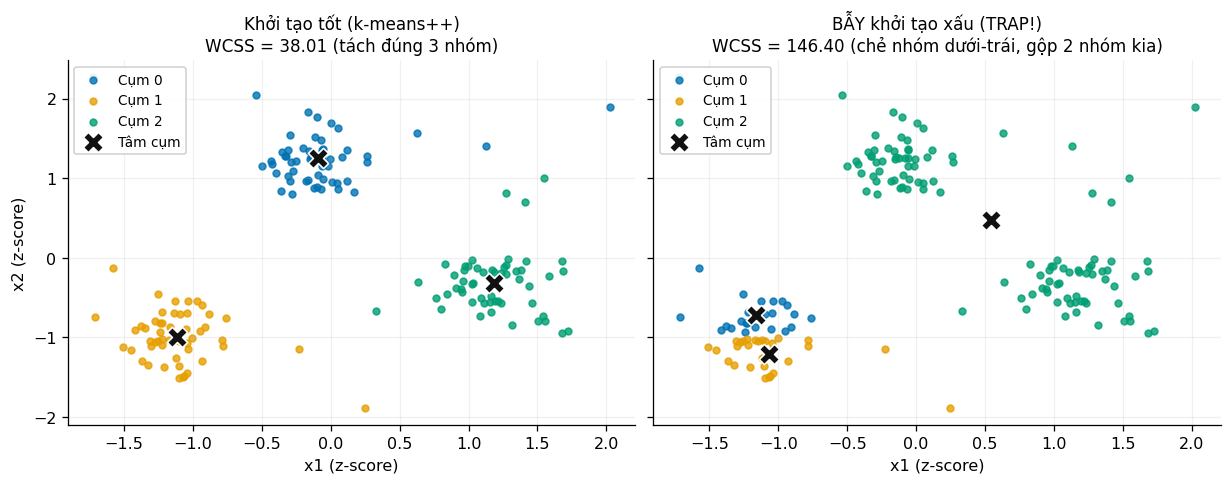

In [4]:
km_good = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=SEED).fit(X)
bad_init = np.array([[-1.10, -0.80], [-1.10, -1.20], [0.60, 0.40]])
km_trap = KMeans(n_clusters=3, init=bad_init, n_init=1, max_iter=50, random_state=SEED).fit(X)

fig, (ax_ok, ax_bad) = plt.subplots(1, 2, figsize=(10.6, 4.1), sharex=True, sharey=True, layout="constrained")
for ax, m, title in (
    (ax_ok, km_good, f"Khởi tạo tốt (k-means++)\nWCSS = {km_good.inertia_:.2f} (tách đúng 3 nhóm)"),
    (ax_bad, km_trap, f"BẪY khởi tạo xấu (TRAP!)\nWCSS = {km_trap.inertia_:.2f} (chẻ nhóm dưới-trái, gộp 2 nhóm kia)"),
):
    for g in range(3):
        ax.scatter(X[m.labels_ == g, 0], X[m.labels_ == g, 1], s=18, c=PAL[g], alpha=0.8, label=f"Cụm {g}")
    ax.scatter(m.cluster_centers_[:, 0], m.cluster_centers_[:, 1], marker="X", s=160, c="#111111",
               edgecolors="white", linewidths=1.0, label="Tâm cụm", zorder=5)
    ax.set_title(title, fontsize=10.5)
    ax.set_xlabel("x1 (z-score)")
    ax.grid(alpha=0.18)
    ax.legend(loc="upper left", fontsize=8.5, framealpha=0.9)
ax_ok.set_ylabel("x2 (z-score)")
plt.show()

### 2.3 Trực quan hóa WCSS (`k = 1` vs `k = 3`), Elbow & Silhouette (slides 27–31)

**WCSS** (Within-Cluster Sum of Squares) cộng bình phương khoảng cách từ mọi điểm tới tâm cụm của nó. Với `k = 1` ("Is 1 centroid good enough?"), khoảng cách từ điểm tới tâm rất lớn; tăng `k` làm WCSS giảm xuống, còn điểm **Elbow** / **Silhouette** giúp chọn `k = 3`.

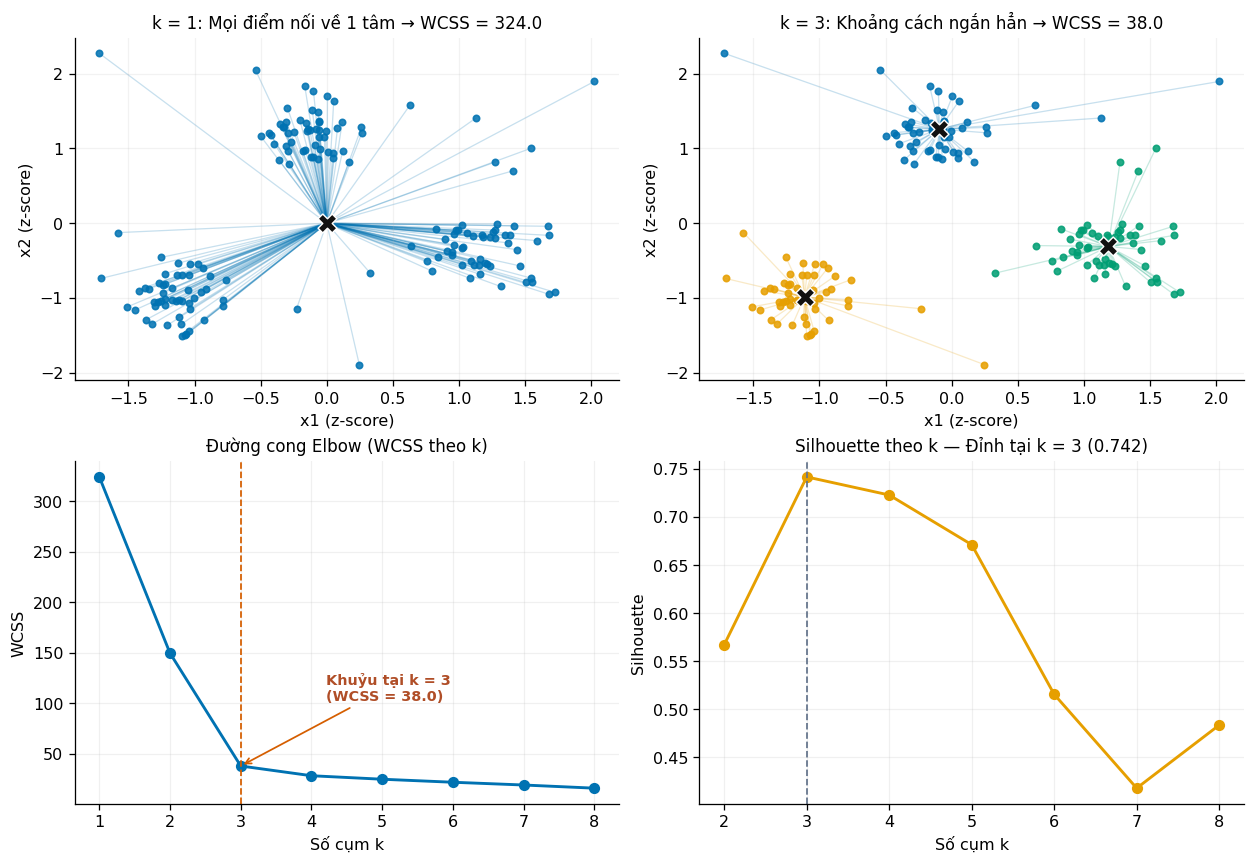

In [5]:
ks = range(1, 9)
wcss = [KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X).inertia_ for k in ks]
sil = [silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X))
       for k in ks if k > 1]
best_k = [k for k in ks if k > 1][int(np.argmax(sil))]

km1 = KMeans(n_clusters=1, n_init=10, random_state=SEED).fit(X)
km3 = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X)

fig, axes = plt.subplots(2, 2, figsize=(10.8, 7.4), layout="constrained")
for ax, m, title in (
    (axes[0, 0], km1, f"k = 1: Mọi điểm nối về 1 tâm → WCSS = {km1.inertia_:.1f}"),
    (axes[0, 1], km3, f"k = 3: Khoảng cách ngắn hẳn → WCSS = {km3.inertia_:.1f}"),
):
    for idx_pt, pt in enumerate(X):
        lbl = int(m.labels_[idx_pt])
        c = m.cluster_centers_[lbl]
        ax.plot([pt[0], c[0]], [pt[1], c[1]], "-", color=PAL[lbl], alpha=0.22, lw=0.8, zorder=1)
    for g in range(m.n_clusters):
        ax.scatter(X[m.labels_ == g, 0], X[m.labels_ == g, 1], s=16, c=PAL[g], alpha=0.85, zorder=3)
    ax.scatter(m.cluster_centers_[:, 0], m.cluster_centers_[:, 1], marker="X", s=140, c="#111111",
               edgecolors="white", lw=0.9, zorder=5)
    ax.set_title(title, fontsize=10.5)
    ax.set_xlabel("x1 (z-score)")
    ax.set_ylabel("x2 (z-score)")
    ax.grid(alpha=0.16)

axes[1, 0].plot(list(ks), wcss, "o-", color=PAL[0], lw=1.8)
axes[1, 0].axvline(3, color="#D55E00", ls="--", lw=1.1)
axes[1, 0].annotate(f"Khuỷu tại k = 3\n(WCSS = {wcss[2]:.1f})", xy=(3, wcss[2]), xytext=(4.2, wcss[2] + 65),
                    fontsize=9, fontweight="bold", color="#B04E27",
                    arrowprops=dict(arrowstyle="->", color="#D55E00", lw=1.1))
axes[1, 0].set_title("Đường cong Elbow (WCSS theo k)", fontsize=10.5)
axes[1, 0].set_xlabel("Số cụm k")
axes[1, 0].set_ylabel("WCSS")
axes[1, 0].grid(alpha=0.18)

axes[1, 1].plot([k for k in ks if k > 1], sil, "o-", color=PAL[1], lw=1.8)
axes[1, 1].axvline(best_k, color="#64748B", ls="--", lw=1.1)
axes[1, 1].set_title(f"Silhouette theo k — Đỉnh tại k = {best_k} ({max(sil):.3f})", fontsize=10.5)
axes[1, 1].set_xlabel("Số cụm k")
axes[1, 1].set_ylabel("Silhouette")
axes[1, 1].grid(alpha=0.18)
plt.show()

## 3. Hierarchical Clustering (Agglomerative) trên đồ thị 2D

### 3.1 Bốn cách đo khoảng cách giữa 2 cụm — Linkage (slide 35)
Minh họa trực tiếp trên đồ thị 2D cho hai cụm $A$ (xanh dương) và $B$ (xanh lá):
`#1 Single` (cặp gần nhất), `#2 Complete` (cặp xa nhất), `#3 Centroid` (khoảng cách hai tâm), `#4 Average` (trung bình mọi cặp).

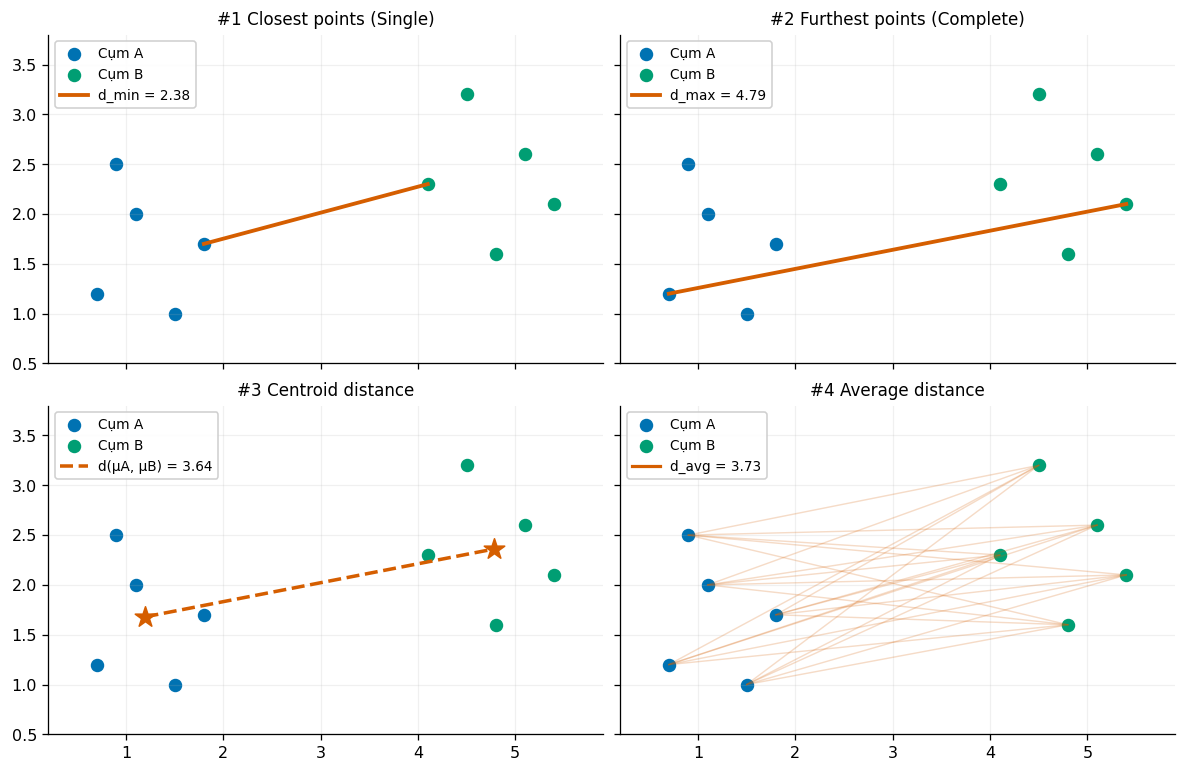

In [6]:
A_pts = np.array([[0.7, 1.2], [1.1, 2.0], [1.5, 1.0], [1.8, 1.7], [0.9, 2.5]])
B_pts = np.array([[4.1, 2.3], [4.5, 3.2], [5.1, 2.6], [4.8, 1.6], [5.4, 2.1]])
D_ab = cdist(A_pts, B_pts)
i_min, j_min = np.unravel_index(np.argmin(D_ab), D_ab.shape)
i_max, j_max = np.unravel_index(np.argmax(D_ab), D_ab.shape)
mu_a, mu_b = A_pts.mean(axis=0), B_pts.mean(axis=0)

fig, axes = plt.subplots(2, 2, figsize=(10.2, 6.6), sharex=True, sharey=True, layout="constrained")
specs = (
    ("#1 Closest points (Single)", "min"),
    ("#2 Furthest points (Complete)", "max"),
    ("#3 Centroid distance", "centroid"),
    ("#4 Average distance", "avg"),
)
for ax, (title, kind) in zip(axes.ravel(), specs, strict=True):
    ax.scatter(A_pts[:, 0], A_pts[:, 1], s=55, c=PAL[0], label="Cụm A")
    ax.scatter(B_pts[:, 0], B_pts[:, 1], s=55, c=PAL[2], label="Cụm B")
    if kind == "min":
        ax.plot([A_pts[i_min, 0], B_pts[j_min, 0]], [A_pts[i_min, 1], B_pts[j_min, 1]],
                "-", color="#D55E00", lw=2.4, label=f"d_min = {D_ab[i_min, j_min]:.2f}")
    elif kind == "max":
        ax.plot([A_pts[i_max, 0], B_pts[j_max, 0]], [A_pts[i_max, 1], B_pts[j_max, 1]],
                "-", color="#D55E00", lw=2.4, label=f"d_max = {D_ab[i_max, j_max]:.2f}")
    elif kind == "centroid":
        ax.scatter([mu_a[0], mu_b[0]], [mu_a[1], mu_b[1]], marker="*", s=180, c="#D55E00", zorder=5)
        ax.plot([mu_a[0], mu_b[0]], [mu_a[1], mu_b[1]], "--", color="#D55E00", lw=2.2,
                label=f"d(μA, μB) = {np.linalg.norm(mu_a - mu_b):.2f}")
    else:
        for pa in A_pts:
            for pb in B_pts:
                ax.plot([pa[0], pb[0]], [pa[1], pb[1]], "-", color="#D55E00", alpha=0.22, lw=0.9)
        ax.plot([], [], "-", color="#D55E00", lw=2.0, label=f"d_avg = {D_ab.mean():.2f}")
    ax.set_title(title, fontsize=10.5)
    ax.set_xlim(0.2, 5.9)
    ax.set_ylim(0.5, 3.8)
    ax.grid(alpha=0.18)
    ax.legend(loc="upper left", fontsize=8.5, framealpha=0.92)
plt.show()

### 3.2 Ghép từng bước trên đồ thị 2D + Dendrogram đặt song song (slides 37–47)

Trên 6 điểm $P_0 \dots P_5$: bên trái là vòng bao ghép dần từ dưới lên (mỗi lần gộp hai cụm gần nhất), bên phải là **Dendrogram** ghi lại đúng độ cao từng lần gộp và **đường cắt ngang ở khoảng trống lớn nhất** (slide 47).

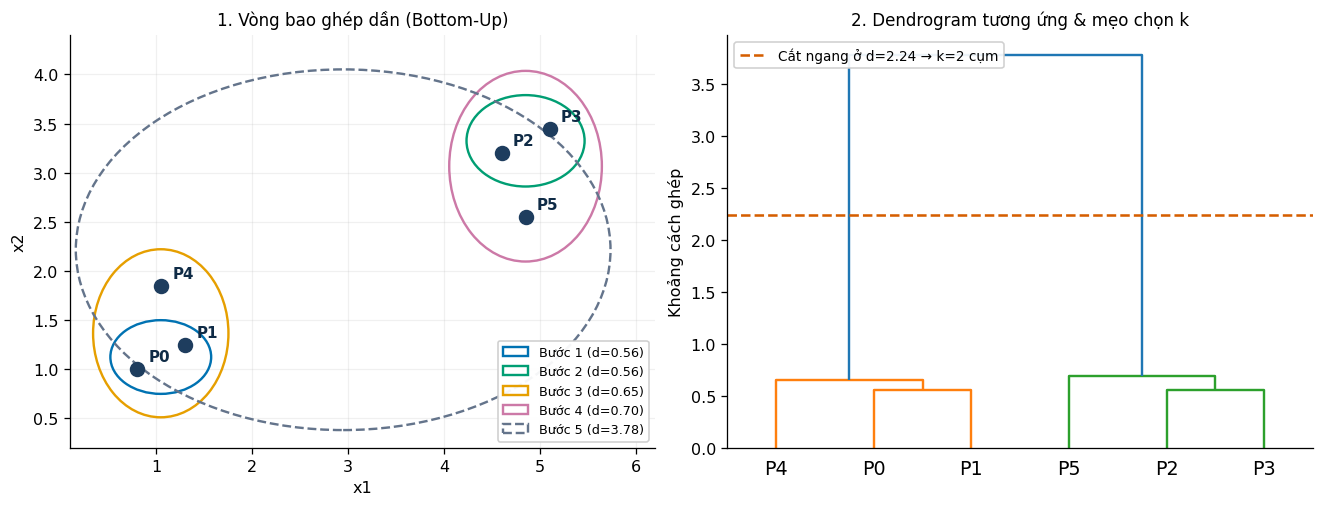

In [7]:
pts6 = np.array([
    [0.8, 1.0], [1.3, 1.25],   # P0, P1: cụm trái
    [4.6, 3.2], [5.1, 3.45],   # P2, P3: cụm phải
    [1.05, 1.85],              # P4: nối với (P0, P1)
    [4.85, 2.55],              # P5: nối với (P2, P3)
])
Z6 = linkage(pts6, method="single")
n6 = len(pts6)
# Theo dõi danh sách thành viên ở mỗi bước ghép
members = {i: [i] for i in range(n6)}
fig, (ax2d, axdn) = plt.subplots(1, 2, figsize=(11.4, 4.3), layout="constrained")
ax2d.scatter(pts6[:, 0], pts6[:, 1], s=75, c="#1E3D5E", zorder=5)
for i, (px, py) in enumerate(pts6):
    ax2d.text(px + 0.12, py + 0.08, f"P{i}", fontsize=9.5, fontweight="bold", color="#0F2B46")

ring_colors = ["#0072B2", "#009E73", "#E69F00", "#CC79A7", "#64748B"]
for step_i, row in enumerate(Z6):
    c1, c2, dist, _ = int(row[0]), int(row[1]), float(row[2]), row[3]
    merged = members[c1] + members[c2]
    members[n6 + step_i] = merged
    sub = pts6[merged]
    cx, cy = sub.mean(axis=0)
    span_x = max(0.80, (sub[:, 0].max() - sub[:, 0].min()) + 0.55 + 0.18 * step_i)
    span_y = max(0.70, (sub[:, 1].max() - sub[:, 1].min()) + 0.50 + 0.18 * step_i)
    ax2d.add_patch(Ellipse((cx, cy), width=span_x, height=span_y, facecolor="none",
                           edgecolor=ring_colors[step_i], linestyle="-" if step_i < 4 else "--",
                           linewidth=1.5, label=f"Bước {step_i + 1} (d={dist:.2f})", zorder=2))

ax2d.set_xlim(0.1, 6.2)
ax2d.set_ylim(0.2, 4.4)
ax2d.set_title("1. Vòng bao ghép dần (Bottom-Up)", fontsize=10.5)
ax2d.set_xlabel("x1")
ax2d.set_ylabel("x2")
ax2d.grid(alpha=0.18)
ax2d.legend(loc="lower right", fontsize=8, framealpha=0.94)

heights6 = Z6[:, 2]
cut_i = int(np.argmax(np.diff(heights6)))
thr6 = float((heights6[cut_i] + heights6[cut_i + 1]) / 2)
k6 = n6 - (cut_i + 1)
dendrogram(Z6, ax=axdn, labels=[f"P{i}" for i in range(n6)], color_threshold=thr6)
axdn.axhline(thr6, color="#D55E00", ls="--", lw=1.6, label=f"Cắt ngang ở d={thr6:.2f} → k={k6} cụm")
axdn.set_title("2. Dendrogram tương ứng & mẹo chọn k", fontsize=10.5)
axdn.set_ylabel("Khoảng cách ghép")
axdn.legend(loc="upper left", fontsize=8.5, framealpha=0.92)
plt.show()

### 3.3 Năm phương pháp Linkage & chọn số cụm trên dữ liệu 162 điểm

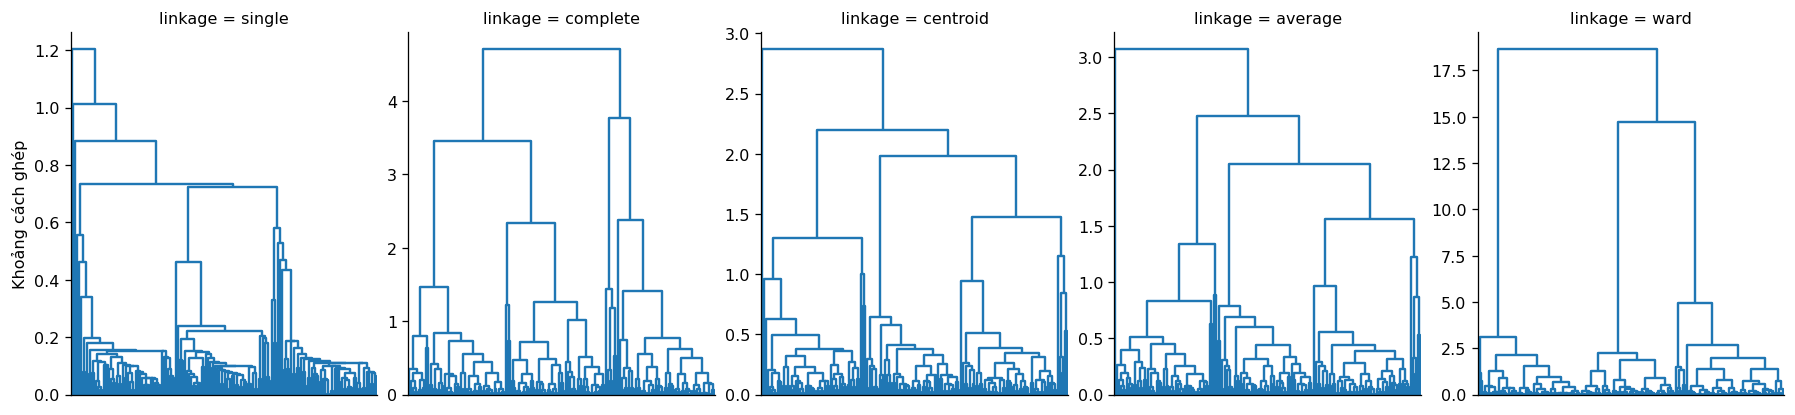

In [8]:
methods = ["single", "complete", "centroid", "average", "ward"]
fig, axes = plt.subplots(1, 5, figsize=(15.5, 3.5), layout="constrained")
for ax, method in zip(axes, methods, strict=True):
    Z = linkage(X, method=method)
    dendrogram(Z, ax=ax, no_labels=True, color_threshold=0)
    ax.set_title(f"linkage = {method}", fontsize=10)
    ax.set_ylabel("Khoảng cách ghép" if method == "single" else "")
plt.show()

Bước nhảy lớn nhất ở lần ghép thứ 159 → k = 3


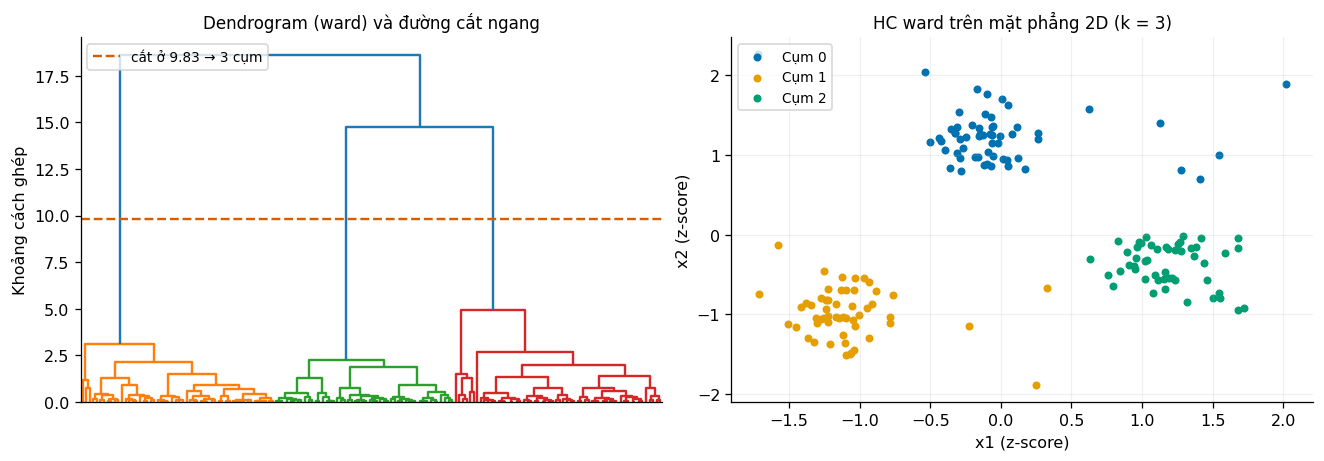

In [9]:
Z = linkage(X, method="ward")
heights = Z[:, 2]
gaps = np.diff(heights)
cut = int(np.argmax(gaps))
k_dendro = len(X) - (cut + 1)
threshold = float((heights[cut] + heights[cut + 1]) / 2)
print(f"Bước nhảy lớn nhất ở lần ghép thứ {cut + 1} → k = {k_dendro}")

hc = AgglomerativeClustering(n_clusters=k_dendro, linkage="ward").fit(X)
fig, (ax_dn, ax_sc) = plt.subplots(1, 2, figsize=(11.4, 3.9), layout="constrained")
dendrogram(Z, ax=ax_dn, no_labels=True, color_threshold=threshold)
ax_dn.axhline(threshold, color="#D55E00", ls="--", lw=1.5, label=f"cắt ở {threshold:.2f} → {k_dendro} cụm")
ax_dn.set_title("Dendrogram (ward) và đường cắt ngang", fontsize=10.5)
ax_dn.set_ylabel("Khoảng cách ghép")
ax_dn.legend(loc="upper left", fontsize=8.5)

for g in range(k_dendro):
    ax_sc.scatter(X[hc.labels_ == g, 0], X[hc.labels_ == g, 1], s=16, c=PAL[g], label=f"Cụm {g}")
ax_sc.set_title(f"HC ward trên mặt phẳng 2D (k = {k_dendro})", fontsize=10.5)
ax_sc.set_xlabel("x1 (z-score)")
ax_sc.set_ylabel("x2 (z-score)")
ax_sc.grid(alpha=0.18)
ax_sc.legend(loc="upper left", fontsize=8.5)
plt.show()

## 4. Đặt STING (4 bước & Bẫy lưới/nhiễu) lên cùng dữ liệu

Khác K-Means và HC (ép mọi điểm kể cả 12 điểm nhiễu vào một cụm), STING chia lưới, đếm điểm trong từng ô, chọn ô dày (`count ≥ min_count`), nối các ô dày qua cạnh và tách riêng các điểm ô thưa thành **nhiễu (−1)**.

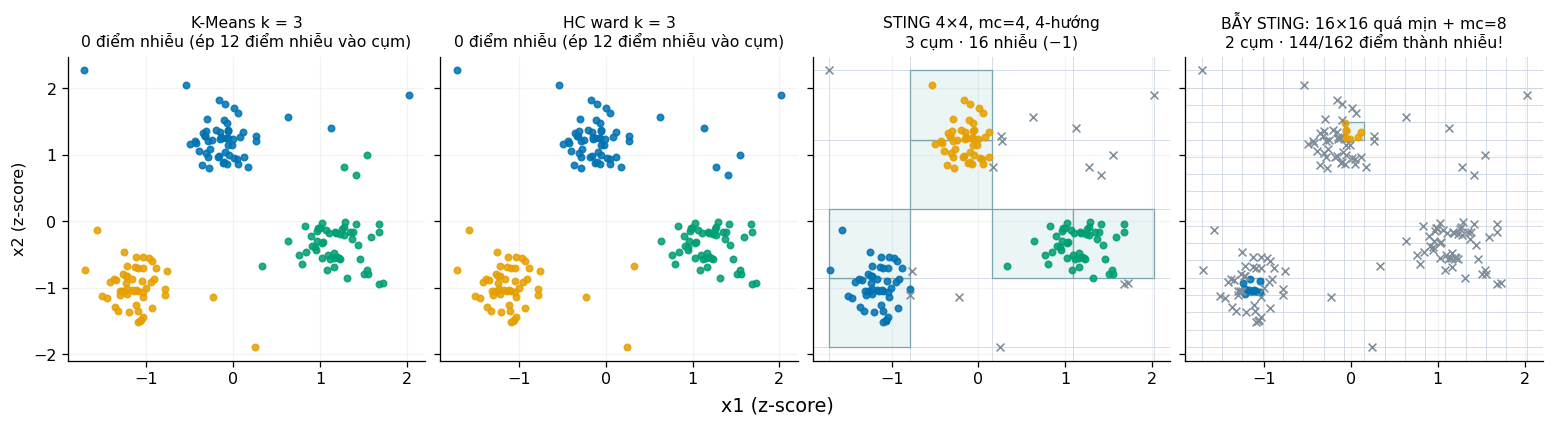

In [10]:
sting_base = STING(n_levels=3, factor=4, min_count=4).fit(X)
lab_4 = sting_base.cluster(level=1, connectivity=1)  # lưới 4×4

sting_high = STING(n_levels=3, factor=4, min_count=8).fit(X)
lab_trap_mc = sting_high.cluster(level=2, connectivity=1)  # lưới 16×16 quá mịn + mc=8

sting_c8 = copy.deepcopy(sting_base)
lab_c8 = sting_c8.cluster(level=1, connectivity=2)

fig, axes = plt.subplots(1, 4, figsize=(13.4, 3.6), sharex=True, sharey=True, layout="constrained")
panels_cmp = (
    (km3.labels_, f"K-Means k = {best_k}\n0 điểm nhiễu (ép 12 điểm nhiễu vào cụm)", None, 0),
    (hc.labels_, f"HC ward k = {k_dendro}\n0 điểm nhiễu (ép 12 điểm nhiễu vào cụm)", None, 0),
    (lab_4, f"STING 4×4, mc=4, 4-hướng\n{sting_base.n_clusters_} cụm · {(lab_4 == -1).sum()} nhiễu (−1)", sting_base, 1),
    (lab_trap_mc, f"BẪY STING: 16×16 quá mịn + mc=8\n{sting_high.n_clusters_} cụm · {(lab_trap_mc == -1).sum()}/{len(X)} điểm thành nhiễu!", sting_high, 2),
)
for ax, (lab, ptitle, m_grid, lvl_g) in zip(axes, panels_cmp, strict=True):
    if m_grid is not None:
        res = m_grid.factor ** lvl_g
        lo, hi = m_grid.bounds_min_, m_grid.bounds_max_
        step = (hi - lo) / res
        for idx in m_grid.label_of_:
            cell = m_grid.cells_[lvl_g][idx]
            ax.add_patch(Rectangle(cell.bounds_min, *(cell.bounds_max - cell.bounds_min),
                                   facecolor="#EBF5F5", edgecolor="#7CA6AD", lw=0.8, zorder=1))
        for i in range(res + 1):
            ax.axvline(lo[0] + i * step[0], color="#CBD5E1", lw=0.5, zorder=0.5)
            ax.axhline(lo[1] + i * step[1], color="#CBD5E1", lw=0.5, zorder=0.5)
    noise = lab == -1
    if noise.any():
        ax.scatter(X[noise, 0], X[noise, 1], c="#7F8C9A", marker="x", s=24, lw=1.0, zorder=4, label="Nhiễu −1")
    for g in sorted(set(lab[~noise])):
        ax.scatter(X[lab == g, 0], X[lab == g, 1], c=PAL[g % len(PAL)], s=16, alpha=0.85, zorder=3)
    ax.set_title(ptitle, fontsize=9.8)
    ax.grid(alpha=0.14)
axes[0].set_ylabel("x2 (z-score)")
fig.supxlabel("x1 (z-score)")
plt.show()

## Tóm tắt để nhớ

| | K-Means | HC (Agglomerative) | STING (nhóm 15) |
|---|---|---|---|
| Cần chọn `k` trước | Có (`WCSS / Silhouette`) | Không (cắt Dendrogram sau) | Không (`level, factor, min_count`) |
| Ý tưởng cốt lõi | Kéo tâm cụm về trung bình | Ghép dần hai cụm gần nhất | Đếm điểm theo ô lưới, nối ô dày |
| Điểm nhiễu (`−1`) | Không tách riêng | Không tách riêng | Tách riêng ô thưa (`count < min_count`) |
| Rủi ro/bẫy đặc trưng | Khởi tạo tâm xấu (`TRAP!`) | Chọn nhầm loại Linkage | `min_count` / độ mịn lưới / `4` vs `8` hướng |